# 3. Cross-validation and replication of niches

This vignette evaluates GRASS-MIL by nested cross-validation (one image per
outer fold), analyses the niches of a fold model on the tiles it never saw, and
asks which niches recur across the fold models. It reuses the encoder pretrained
in vignette 2.

With three images, the folds are small: the numbers illustrate the procedure,
not the performance of the method.

In [1]:
import json
import pathlib
import subprocess

import pandas as pd
from IPython.display import Image, Markdown, display

WORK = pathlib.Path("vignette_work").resolve()
DATA = WORK / "data"
COHORT = json.loads((WORK / "cohort.json").read_text())  # written by vignette 1

# Fine-tuning on a handful of tiles: a stronger probe penalty (the default C=1
# suits tens of thousands of ego-graphs) and more optimizer steps per epoch.
SMALL_DATA = ["finetune.probe.C=0.01", "finetune.hyperbatch_size=4"]


def run(command, *overrides):
    """Run a grass-mil command; show the end of its log if it fails.

    Commands that read the cohort (train, nested-cv, extract) get its settings;
    the analysis commands read a cell cache instead.
    """
    cohort = COHORT["overrides"] if command in ("grass-mil-train", "grass-mil-nested-cv", "grass-mil-extract") else []
    result = subprocess.run([command, *cohort, *overrides], capture_output=True, text=True)
    if result.returncode:
        print(result.stderr[-4000:])
        raise RuntimeError(f"{command} failed")

ENCODER = WORK / "pretrain" / "checkpoints" / "last.ckpt"

## Nested cross-validation

For every outer fold, the other two images are split into inner folds (here
`inner_k=2`, one image each); every inner run reports its best epoch, and the
model is refitted on both images for the median of those epochs and scored on
the held-out image.

In [2]:
run(
    "grass-mil-nested-cv",
    f"model.init_from_ckpt={ENCODER}",
    *SMALL_DATA,
    f"nested_cv.folds_file={DATA / 'folds.json'}",
    "nested_cv.inner_k=2",
    "trainer.max_epochs=20",
    "trainer.min_epochs=5",
    f"hydra.run.dir={WORK / 'nested_cv'}",
)
CV = WORK / "nested_cv"
summary = json.loads((CV / "nested_cv_summary.json").read_text())
print(f"AUROC per held-out image: {[round(v, 3) for v in summary['fold_values']]}")
print(f"mean ± s.d.: {summary['mean']:.3f} ± {summary['sd']:.3f}; pooled: {summary['pooled']['auroc']:.3f}")
pd.read_csv(CV / "oof_predictions.csv").round(3).head()

AUROC per held-out image: [0.783, 0.943, 0.909]
mean ± s.d.: 0.878 ± 0.084; pooled: 0.773


,outer,unit_id,prob_0,prob_1,pred,label,region_id,sample_id,patient_id
0,0,point16_tile000,0.042,0.958,1,1,point16,point16,point16
1,0,point16_tile001,0.152,0.848,1,1,point16,point16,point16
2,0,point16_tile002,0.446,0.554,1,1,point16,point16,point16
3,0,point16_tile003,0.925,0.075,0,1,point16,point16,point16
4,0,point16_tile004,0.268,0.732,1,1,point16,point16,point16


## Per-cell outputs of every fold model

Each fold model scores every tile; the cache records which tiles it held out.

In [3]:
run(
    "grass-mil-extract",
    f"extract.nested_cv_summary={CV / 'nested_cv_summary.json'}",
    f"extract.output_dir={WORK / 'cv_cells'}",
    f"hydra.run.dir={WORK / 'cv_extract'}",
)
sorted(p.name for p in (WORK / "cv_cells").iterdir())

['fold0', 'fold1', 'fold2']

## Niches of one fold model, on its held-out tiles

By default `grass-mil-niches` analyses the units the model did not train on;
as in vignette 2, leaf selection suits the small number of cells.

,niche,share,association,margin,margin_lo,margin_hi,composition
0,Niche 1,0.326,0.811,6.811,4.804,8.612,"Tcell_CD4 27%, Tcell_CD8 27%, Fibroblast 13%"
1,Niche 2,0.120,1.000,6.554,3.830,9.890,"Epithelial 42%, Tcell_CD8 27%, Tcell_CD4 13%"
2,Niche 3,0.030,0.258,6.439,4.228,8.423,"Fibroblast 42%, Tcell_CD4 23%, Imm_other 19%"
3,Niche 4,0.091,0.667,4.968,2.498,7.114,"Tcell_CD4 28%, Epithelial 20%, Tcell_CD8 17%"
4,Niche 5,0.060,0.869,4.832,2.681,6.717,"Tcell_CD8 30%, Tcell_CD4 23%, Epithelial 20%"
5,Niche 6,0.030,0.742,3.537,0.765,5.488,"Tcell_CD8 32%, Tcell_CD4 26%, Epithelial 16%"
6,Niche 7,0.029,0.000,2.438,2.438,2.438,"Fibroblast 60%, Imm_other 17%, Tcell_CD4 17%"
7,Background,0.314,0.495,4.780,2.791,6.657,"Epithelial 30%, Tcell_CD4 18%, Tcell_CD8 17%"


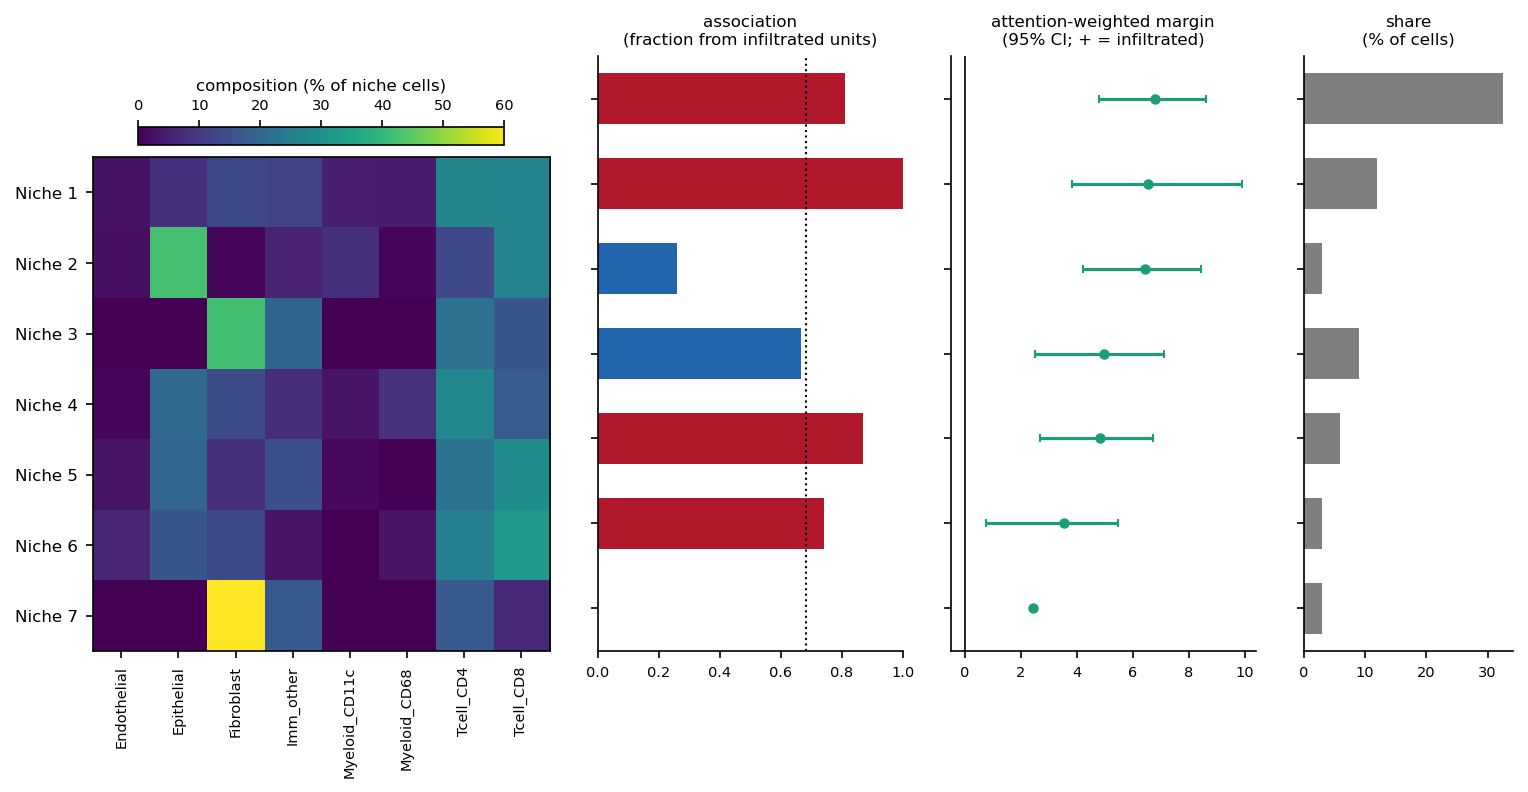

In [4]:
run(
    "grass-mil-niches",
    f"cells_dir={WORK / 'cv_cells' / 'fold0'}",
    "clustering.min_cluster_size=30",
    "clustering.selection=leaf",
    "positive_name=infiltrated",
    f"hydra.run.dir={WORK / 'cv_niches'}",
)
display(pd.read_csv(WORK / "cv_niches" / "niches.csv")[["niche", "share", "association", "margin", "margin_lo", "margin_hi", "composition"]].round(3))
display(Image(WORK / "cv_niches" / "figures" / "niche_panel.png"))

## Replication across fold models (optional)

Every fold model has its own embedding, so its niches are discovered on its own
held-out tiles. `grass-mil-metaclusters` matches niches of different models by
their cell-type composition; a metacluster found by at least `min_models`
models is replicated.

,metacluster,n_models,replicated,margin,association_vs_base,composition
0,M1,3,True,9.722,0.131,"Tcell_CD4 30%, Tcell_CD8 24%, Fibroblast 12%"
1,M2,3,True,7.582,-0.141,"Epithelial 41%, Tcell_CD8 18%, Tcell_CD4 17%"
2,M3,3,True,10.872,-0.023,"Imm_other 25%, Tcell_CD4 20%, Fibroblast 17%"
3,M4,3,True,9.627,0.026,"Tcell_CD4 31%, Epithelial 20%, Myeloid_CD68 11%"
4,M5,3,True,9.538,0.093,"Tcell_CD4 31%, Epithelial 17%, Imm_other 15%"
5,M6,3,True,7.290,-0.131,"Tcell_CD4 39%, Epithelial 27%, Tcell_CD8 16%"
6,M7,2,True,3.085,-0.452,"Fibroblast 39%, Epithelial 23%, Imm_other 14%"
7,M8,2,True,15.789,0.521,"Tcell_CD4 25%, Imm_other 23%, Myeloid_CD68 22%"
8,M9,1,False,23.907,0.177,"Tcell_CD4 36%, Imm_other 35%, Tcell_CD8 16%"
9,M10,1,False,23.857,0.347,"Tcell_CD4 50%, Tcell_CD8 21%, Imm_other 11%"


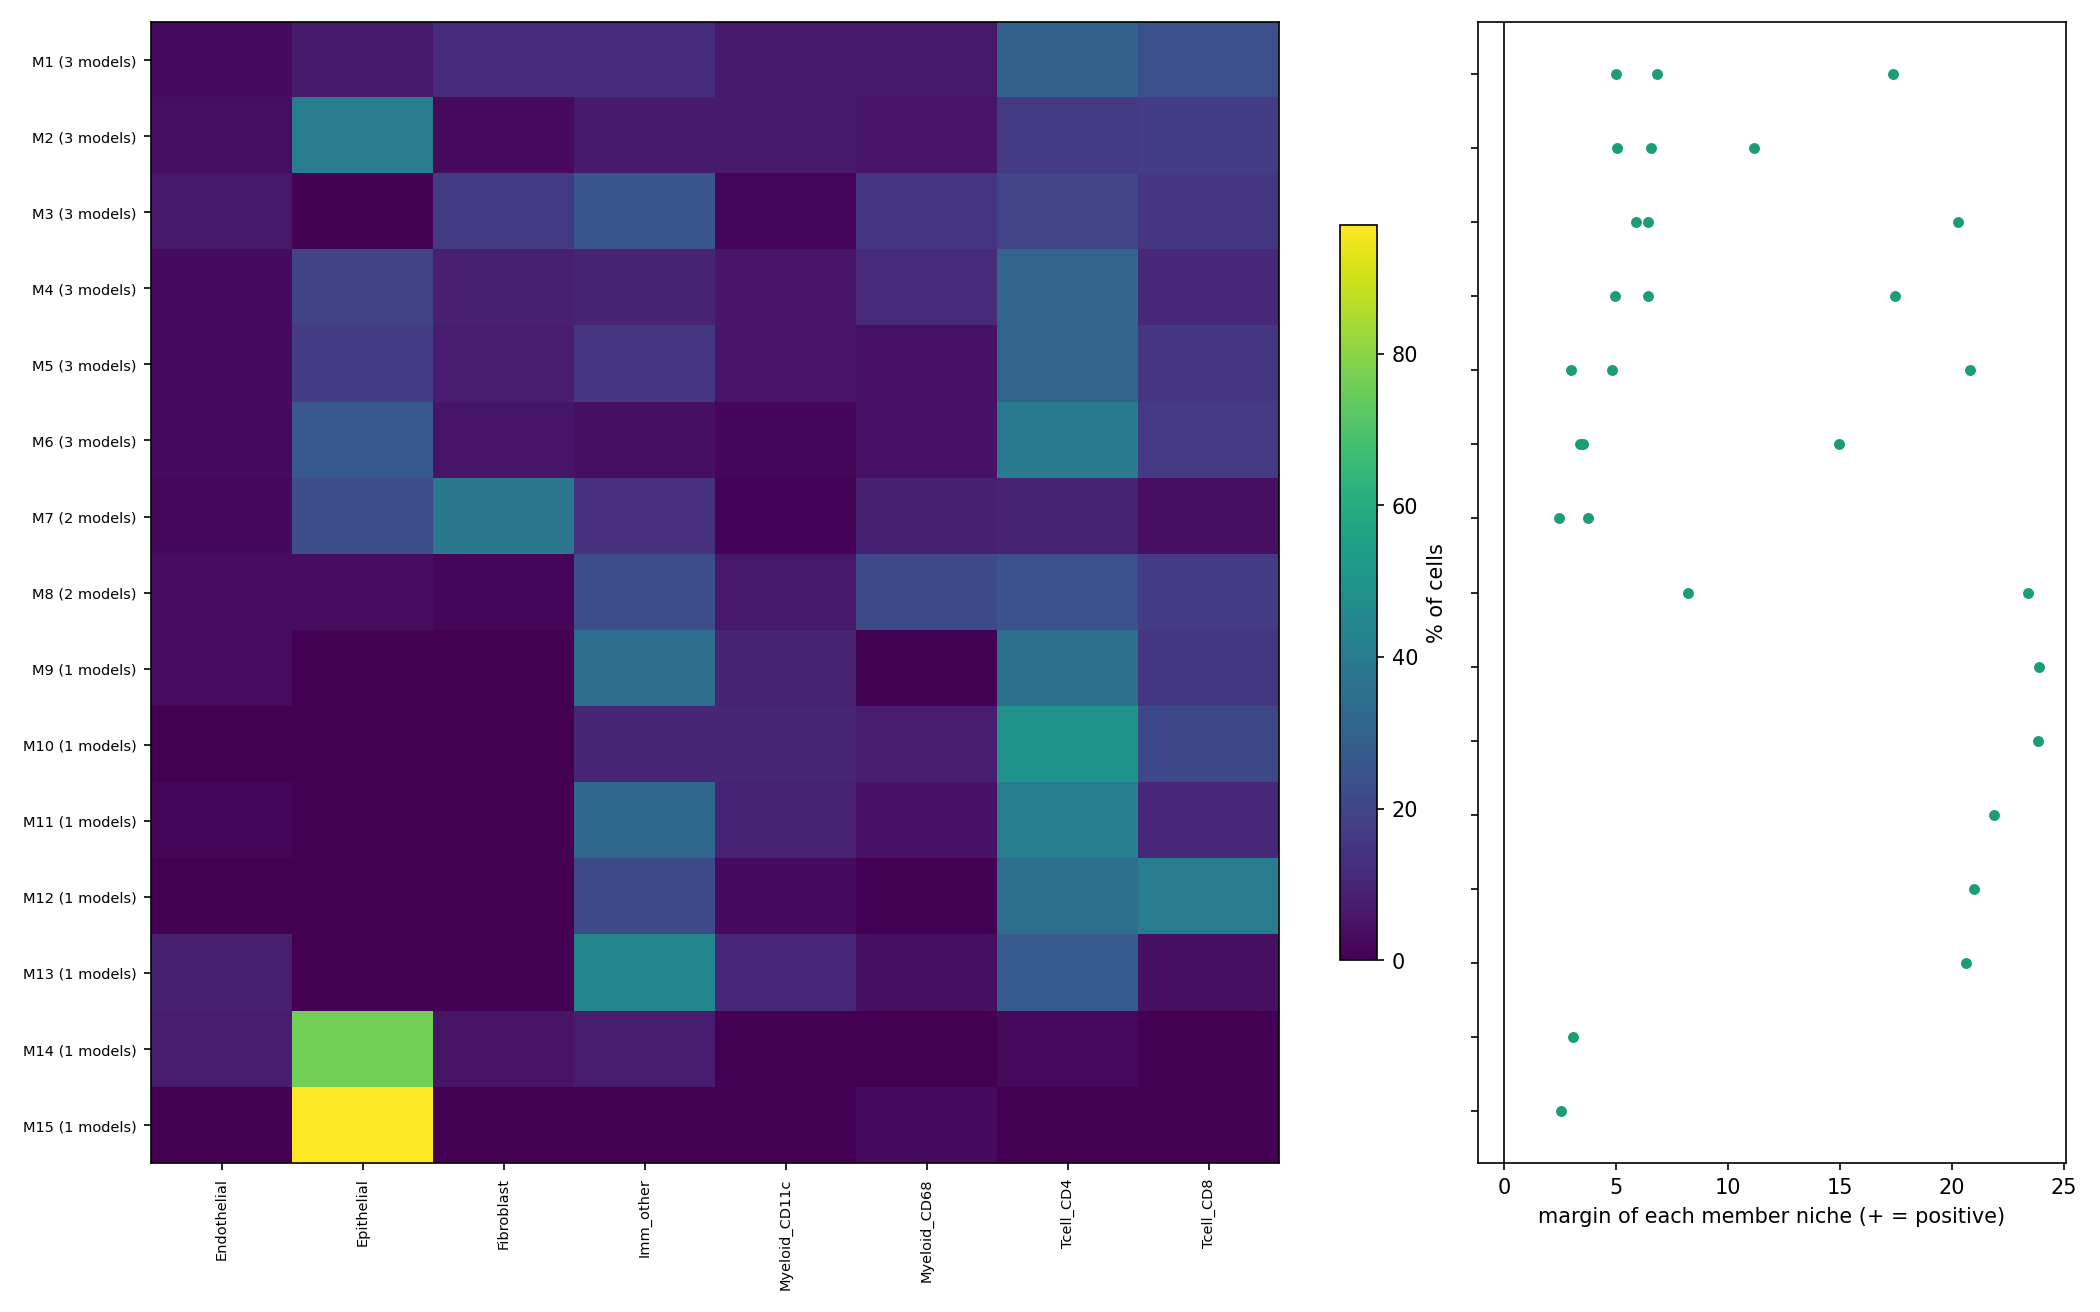

In [5]:
run(
    "grass-mil-metaclusters",
    f"cells_dir={WORK / 'cv_cells'}",
    "+clustering.min_cluster_size=30",
    "+clustering.selection=leaf",
    "match.min_models=2",
    "basis.k=6",
    f"hydra.run.dir={WORK / 'metaclusters'}",
)
META = WORK / "metaclusters"
display(pd.read_csv(META / "metaclusters.csv")[["metacluster", "n_models", "replicated", "margin", "association_vs_base", "composition"]].round(3))
display(Image(META / "metaclusters.png"))

## Model-free spatial statistics (optional)

The same cells, without a model: neighbourhood enrichment, cellular
neighbourhoods, and contacts and cross-L of epithelial cells with every other
type, compared between infiltrated and other tiles (`compare_by=unit`; on a
cohort, patients are compared, each summarised by the mean over its units).

In [6]:
run(
    "grass-mil-spatial-stats",
    f"cells_dir={WORK / 'cv_cells' / 'fold0'}",
    "reference=[Epithelial]",
    "compare_by=unit",
    "min_patients=3",
    f"hydra.run.dir={WORK / 'spatial_stats'}",
)
pd.read_csv(WORK / "spatial_stats" / "contacts_tests.csv").round(4).head(8)

,metric,n_pos,n_neg,mean_pos,mean_neg,p,diff,q
0,Epithelial->Epithelial,7,15,0.4995,0.8126,0.0213,-0.3131,0.0945
1,Epithelial->Tcell_CD8,7,15,0.0967,0.0149,0.0236,0.0818,0.0945
2,Epithelial->Tcell_CD4,7,15,0.1793,0.0355,0.0462,0.1439,0.1232
3,Epithelial->Myeloid_CD68,7,15,0.0631,0.0430,0.1590,0.0202,0.3180
4,Epithelial->Endothelial,7,15,0.0372,0.0177,0.2826,0.0194,0.4522
5,Epithelial->Myeloid_CD11c,7,15,0.0527,0.0256,0.5666,0.0271,0.7555
6,Epithelial->Fibroblast,7,15,0.0198,0.0077,0.9674,0.0121,1.0000
7,Epithelial->Imm_other,7,15,0.0516,0.0430,1.0000,0.0086,1.0000
